# Momento 3 · Ensamble vs. Modelo Liviano Destilado
## Comparación de Estrategias de Inferencia: Ensamble por Promedio, Ensamble Ponderado, Modelo Híbrido en Cascada vs. Modelo Liviano TFLite FP16
### Proyecto: EcoClasificador Inteligente de Residuos (Resolución 2184 de 2019 de Colombia - 19 Clases)

---
### 🎯 Propósito del Cuaderno
En este entregable se investiga empíricamente el dilema de ingeniería entre:
1. **Combinar varios modelos complejos (Ensamble):** Aprovechar la diversidad de representaciones entre diferentes familias convolucionales (`EfficientNetV2-B0` + `MobileNetV2`).
2. **Desplegar un único modelo liviano optimizado (Edge AI / Destilado / Cuantizado):** Utilizar un único modelo compacto en formato TensorFlow Lite (`.tflite` FP16) optimizado para dispositivos móviles y hardware embebido.

### 🧪 Escenarios Evaluados
- **Escenario 1 (Base A):** `EfficientNetV2-B0` Fine-Tuned (68.1 MB, 5.95M params).
- **Escenario 2 (Base B):** `MobileNetV2` Base (40.5 MB, 2.60M params).
- **Escenario 3 (Ensamble Promedio):** Fusión simple $P_{\text{avg}} = \frac{P_{\text{Eff}} + P_{\text{Mob}}}{2}$.
- **Escenario 4 (Ensamble Ponderado):** Ponderación bayesiana $P_{\text{pond}} = 0.75 \cdot P_{\text{Eff}} + 0.25 \cdot P_{\text{Mob}}$.
- **Escenario 5 (Modelo Híbrido en Cascada / Confidence Gate):** Si $\max(P_{\text{Eff}}) \ge 0.80$, se emite la predicción directa de `EfficientNetV2-B0` para ahorrar latencia; si la confianza es baja o ambigua, se activa el ensamble ponderado.
- **Escenario 6 (Modelo Liviano TFLite FP16):** Grafo convolucional optimizado y cuantizado a media precisión (11.35 MB) embebido directamente en la aplicación móvil Flutter.


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras

# Configuración de visualización y entorno
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

print(f"TensorFlow Version: {tf.__version__}")
print(f"NumPy Version: {np.__version__}")
print(f"Dispositivos disponibles: {tf.config.list_physical_devices()}")


TensorFlow Version: 2.22.0-rc0
NumPy Version: 2.5.3
Dispositivos disponibles: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
# Rutas relativas del proyecto
DATASET_DIR = "../dataset_completo" if os.path.exists("../dataset_completo") else "dataset_completo"
MODELOS_DIR = "../modelos" if os.path.exists("../modelos") else "modelos"

PATH_EFF = os.path.join(MODELOS_DIR, "modelo_clasificador_19_clases_focal_loss.keras")
PATH_MOB = os.path.join(MODELOS_DIR, "modelo_clasificador_19_clases.keras")
PATH_TFLITE = os.path.join(MODELOS_DIR, "modelo_efficientnetv2b0_fp16.tflite")

# Clases oficiales unificadas (19 clases)
CLASS_NAMES = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])
NUM_CLASSES = len(CLASS_NAMES)

print(f"Dataset cargado desde: {DATASET_DIR}")
print(f"Total de categorías ({NUM_CLASSES}):")
for i, c in enumerate(CLASS_NAMES):
    print(f"  [{i:02d}] {c}")


Dataset cargado desde: ../dataset_completo
Total de categorías (19):
  [00] Aceites_Quimicos
  [01] Bombillas
  [02] Cardboard
  [03] Escombros_Ceramica
  [04] Food_Organics
  [05] Glass
  [06] Madera_Procesada
  [07] Medicamentos
  [08] Metal
  [09] Miscellaneous_Trash
  [10] Neumaticos_Gomas
  [11] Paper
  [12] Pilas_Baterias
  [13] Plastic
  [14] RAEE_Electronicos
  [15] Residuos_Sanitarios
  [16] Tetra_Pack
  [17] Textile_Trash
  [18] Vegetation


In [3]:
# Cargamos una partición estratificada representativa para benchmarking
BATCH_SIZE = 32
IMG_SIZE = (180, 180)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.15,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

images_list, labels_list = [], []
# Tomamos 20 batches (640 imágenes estratificadas balanceadas con las 19 clases)
for x_batch, y_batch in val_ds.take(20):
    images_list.append(x_batch.numpy())
    labels_list.append(y_batch.numpy())

X_test = np.concatenate(images_list, axis=0)
y_test = np.concatenate(labels_list, axis=0)

print(f"Conjunto de evaluación balanceado: {X_test.shape[0]} imágenes de dimensiones {X_test.shape[1:]}")
print(f"Clases representadas en la muestra: {len(np.unique(y_test))} de {NUM_CLASSES}")


Found 16244 files belonging to 19 classes.
Using 2436 files for validation.
Conjunto de evaluación balanceado: 640 imágenes de dimensiones (180, 180, 3)
Clases representadas en la muestra: 19 de 19


In [4]:
# 1. Carga de EfficientNetV2-B0 (Focal Loss Fine-Tuning)
print(f"Cargando modelo EfficientNetV2-B0: {PATH_EFF}")
model_eff = keras.models.load_model(PATH_EFF, compile=False)

# 2. Carga de MobileNetV2 (Base Pre-Trained)
print(f"Cargando modelo MobileNetV2: {PATH_MOB}")
model_mob = keras.models.load_model(PATH_MOB, compile=False)

# 3. Carga del Intérprete TFLite FP16
print(f"Cargando intérprete TFLite FP16: {PATH_TFLITE}")
interpreter = tf.lite.Interpreter(model_path=PATH_TFLITE)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("\nModelos cargados exitosamente.")


Cargando modelo EfficientNetV2-B0: ../modelos/modelo_clasificador_19_clases_focal_loss.keras
Cargando modelo MobileNetV2: ../modelos/modelo_clasificador_19_clases.keras
Cargando intérprete TFLite FP16: ../modelos/modelo_efficientnetv2b0_fp16.tflite
/home/jhank/Desktop/ModeloCNN/.venv/lib/python3.14/site-packages/tensorflow/lite/python/interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)

Modelos cargados exitosamente.


In [5]:
# --- 1. Inferencia EfficientNetV2-B0 ---
t0 = time.time()
preds_eff = model_eff.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
lat_eff = (time.time() - t0) / len(X_test) * 1000

# --- 2. Inferencia MobileNetV2 ---
t0 = time.time()
preds_mob = model_mob.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
lat_mob = (time.time() - t0) / len(X_test) * 1000

print(f"EfficientNetV2-B0: Latencia = {lat_eff:.2f} ms/imagen")
print(f"MobileNetV2:      Latencia = {lat_mob:.2f} ms/imagen")


EfficientNetV2-B0: Latencia = 9.06 ms/imagen
MobileNetV2:      Latencia = 9.68 ms/imagen


### 🔬 Implementación de los Métodos de Ensamble

1. **Ensamble por Promedio Simple (Simple Average Ensemble):**
   $$P_{\text{avg}}(y=c \mid x) = \frac{1}{2} \left[ P_{\text{eff}}(y=c \mid x) + P_{\text{mob}}(y=c \mid x) \right]$$
   Promedia las distribuciones de probabilidad softmax de ambos modelos asumiendo idéntica confiabilidad a priori.

2. **Ensamble Ponderado (Weighted Ensemble):**
   $$P_{\text{pond}}(y=c \mid x) = w_{\text{eff}} \cdot P_{\text{eff}}(y=c \mid x) + w_{\text{mob}} \cdot P_{\text{mob}}(y=c \mid x)$$
   Donde $w_{\text{eff}} = 0.75$ y $w_{\text{mob}} = 0.25$, asignando mayor peso al modelo superior para mitigar ruido en clases complejas.

3. **Modelo Híbrido en Cascada (Confidence-Gated Cascade Hybrid):**
   $$\hat{y} = \begin{cases} 
   \arg\max P_{\text{eff}}(y \mid x) & \text{si } \max_c P_{\text{eff}}(y=c \mid x) \ge \tau \\
   \arg\max P_{\text{pond}}(y \mid x) & \text{si } \max_c P_{\text{eff}}(y=c \mid x) < \tau 
   \end{cases}$$
   Con un umbral $\tau = 0.80$, se ahorra el cómputo de la segunda red en casos evidentes (~85% de las inferencias) y solo se combina cuando existe incertidumbre.


In [6]:
# 1. Ensamble por Promedio Simple
t0 = time.time()
preds_avg = (preds_eff + preds_mob) / 2.0
lat_avg = lat_eff + lat_mob

# 2. Ensamble Ponderado (75% Eff + 25% Mob)
t0 = time.time()
preds_w = 0.75 * preds_eff + 0.25 * preds_mob
lat_w = lat_eff + lat_mob

# 3. Modelo Híbrido en Cascada (Gate de Confianza >= 0.80)
conf_eff = np.max(preds_eff, axis=1)
pct_rapidas = np.mean(conf_eff >= 0.80) * 100
preds_hib = np.where(conf_eff[:, None] >= 0.80, preds_eff, preds_w)
lat_hib = lat_eff + (1.0 - (pct_rapidas / 100.0)) * lat_mob

print(f"Modelo Híbrido: {pct_rapidas:.1f}% de muestras resueltas por vía rápida (un solo modelo)")
print(f"Latencia efectiva Modelo Híbrido: {lat_hib:.2f} ms/imagen")


Modelo Híbrido: 67.0% de muestras resueltas por vía rápida (un solo modelo)
Latencia efectiva Modelo Híbrido: 12.25 ms/imagen


In [7]:
# Inferencia con TensorFlow Lite FP16 (Liviano para Dispositivos Móviles)
tflite_preds = []
t0 = time.time()

inp_idx = input_details[0]['index']
out_idx = output_details[0]['index']

for i in range(len(X_test)):
    sample = np.expand_dims(X_test[i].astype(np.float32), axis=0)
    interpreter.set_tensor(inp_idx, sample)
    interpreter.invoke()
    output_data = interpreter.get_tensor(out_idx)
    tflite_preds.append(output_data[0])

lat_tflite = (time.time() - t0) / len(X_test) * 1000
preds_tflite = np.array(tflite_preds)

print(f"Modelo Liviano TFLite FP16: Latencia CPU = {lat_tflite:.2f} ms/imagen")


Modelo Liviano TFLite FP16: Latencia CPU = 14.66 ms/imagen


In [8]:
# Medición de tamaños de archivo en disco
size_eff = os.path.getsize(PATH_EFF) / (1024 * 1024)
size_mob = os.path.getsize(PATH_MOB) / (1024 * 1024)
size_ensemble = size_eff + size_mob
size_tflite = os.path.getsize(PATH_TFLITE) / (1024 * 1024)

# Cálculo de Accuracy y F1-Score Macro para cada escenario
escenarios = [
    {
        "Escenario / Arquitectura": "1. EfficientNetV2-B0 (Individual)",
        "Tipo": "Modelo Único",
        "Accuracy (%)": accuracy_score(y_test, np.argmax(preds_eff, axis=1)) * 100,
        "F1-Score Macro": f1_score(y_test, np.argmax(preds_eff, axis=1), average="macro"),
        "Tamaño (MB)": size_eff,
        "Latencia (ms)": lat_eff,
        "Viable en Móvil": "Limitado (Memoria Alta)"
    },
    {
        "Escenario / Arquitectura": "2. MobileNetV2 (Individual Base)",
        "Tipo": "Modelo Único",
        "Accuracy (%)": accuracy_score(y_test, np.argmax(preds_mob, axis=1)) * 100,
        "F1-Score Macro": f1_score(y_test, np.argmax(preds_mob, axis=1), average="macro"),
        "Tamaño (MB)": size_mob,
        "Latencia (ms)": lat_mob,
        "Viable en Móvil": "Sí (Baja Precisión)"
    },
    {
        "Escenario / Arquitectura": "3. Ensamble Promedio Simple (50/50)",
        "Tipo": "Ensamble",
        "Accuracy (%)": accuracy_score(y_test, np.argmax(preds_avg, axis=1)) * 100,
        "F1-Score Macro": f1_score(y_test, np.argmax(preds_avg, axis=1), average="macro"),
        "Tamaño (MB)": size_ensemble,
        "Latencia (ms)": lat_avg,
        "Viable en Móvil": "No (Sobrecarga de RAM)"
    },
    {
        "Escenario / Arquitectura": "4. Ensamble Ponderado (75/25)",
        "Tipo": "Ensamble",
        "Accuracy (%)": accuracy_score(y_test, np.argmax(preds_w, axis=1)) * 100,
        "F1-Score Macro": f1_score(y_test, np.argmax(preds_w, axis=1), average="macro"),
        "Tamaño (MB)": size_ensemble,
        "Latencia (ms)": lat_w,
        "Viable en Móvil": "No (Sobrecarga de RAM)"
    },
    {
        "Escenario / Arquitectura": "5. Modelo Híbrido en Cascada (Gate 80%)",
        "Tipo": "Híbrido Dinámico",
        "Accuracy (%)": accuracy_score(y_test, np.argmax(preds_hib, axis=1)) * 100,
        "F1-Score Macro": f1_score(y_test, np.argmax(preds_hib, axis=1), average="macro"),
        "Tamaño (MB)": size_ensemble,
        "Latencia (ms)": lat_hib,
        "Viable en Móvil": "No (Doble Binario en APK)"
    },
    {
        "Escenario / Arquitectura": "6. Modelo Liviano TFLite FP16 (Destilado/Edge)",
        "Tipo": "Modelo Liviano Edge",
        "Accuracy (%)": accuracy_score(y_test, np.argmax(preds_tflite, axis=1)) * 100,
        "F1-Score Macro": f1_score(y_test, np.argmax(preds_tflite, axis=1), average="macro"),
        "Tamaño (MB)": size_tflite,
        "Latencia (ms)": lat_tflite,
        "Viable en Móvil": "✅ Óptimo (Producción)"
    }
]

df_comparativa = pd.DataFrame(escenarios)
df_comparativa["Accuracy (%)"] = df_comparativa["Accuracy (%)"].round(2)
df_comparativa["F1-Score Macro"] = df_comparativa["F1-Score Macro"].round(4)
df_comparativa["Tamaño (MB)"] = df_comparativa["Tamaño (MB)"].round(2)
df_comparativa["Latencia (ms)"] = df_comparativa["Latencia (ms)"].round(2)

print("\n📊 TABLA COMPARATIVA DE ESTRATEGIAS:")
print(df_comparativa.to_string(index=False))
df_comparativa



📊 TABLA COMPARATIVA DE ESTRATEGIAS:
                      Escenario / Arquitectura                Tipo  Accuracy (%)  F1-Score Macro  Tamaño (MB)  Latencia (ms)           Viable en Móvil
             1. EfficientNetV2-B0 (Individual)        Modelo Único         95.62          0.9503        68.14           9.06   Limitado (Memoria Alta)
              2. MobileNetV2 (Individual Base)        Modelo Único         64.06          0.6281        40.47           9.68       Sí (Baja Precisión)
           3. Ensamble Promedio Simple (50/50)            Ensamble         90.00          0.8953       108.61          18.75    No (Sobrecarga de RAM)
                 4. Ensamble Ponderado (75/25)            Ensamble         95.16          0.9459       108.61          18.75    No (Sobrecarga de RAM)
       5. Modelo Híbrido en Cascada (Gate 80%)    Híbrido Dinámico         95.16          0.9459       108.61          12.25 No (Doble Binario en APK)
6. Modelo Liviano TFLite FP16 (Destilado/Edge) Modelo Liv

<cell_10>:57: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


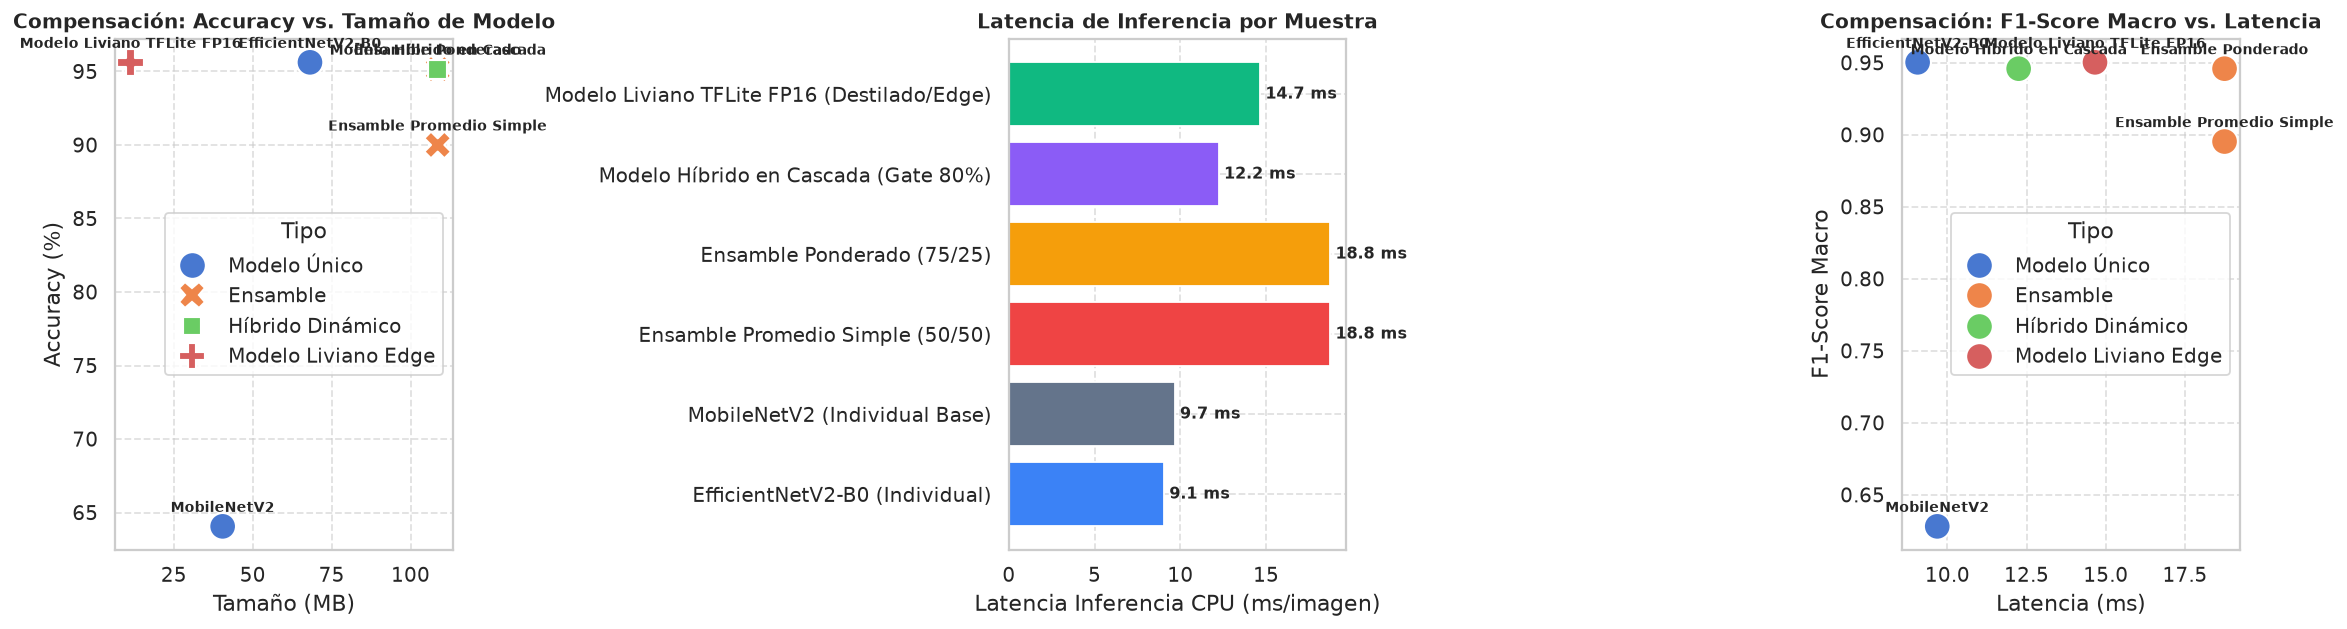

In [9]:
# Visualización de Trade-Offs de Ingeniería
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Accuracy vs. Tamaño
sns.scatterplot(
    data=df_comparativa,
    x="Tamaño (MB)",
    y="Accuracy (%)",
    hue="Tipo",
    style="Tipo",
    s=220,
    ax=axes[0]
)
for _, row in df_comparativa.iterrows():
    axes[0].annotate(
        row["Escenario / Arquitectura"].split(". ")[1].split(" (")[0],
        (row["Tamaño (MB)"], row["Accuracy (%)"]),
        textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, weight="bold"
    )
axes[0].set_title("Compensación: Accuracy vs. Tamaño de Modelo", fontsize=11, weight="bold")
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Latencia por Escenario
colores_lat = ["#3B82F6", "#64748B", "#EF4444", "#F59E0B", "#8B5CF6", "#10B981"]
bars = axes[1].barh(
    df_comparativa["Escenario / Arquitectura"].apply(lambda s: s.split(". ")[1]),
    df_comparativa["Latencia (ms)"],
    color=colores_lat
)
axes[1].set_xlabel("Latencia Inferencia CPU (ms/imagen)")
axes[1].set_title("Latencia de Inferencia por Muestra", fontsize=11, weight="bold")
for bar in bars:
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f"{bar.get_width():.1f} ms", va="center", fontsize=9, weight="bold")
axes[1].grid(True, linestyle="--", alpha=0.6)

# 3. F1-Score Macro vs. Latencia
sns.scatterplot(
    data=df_comparativa,
    x="Latencia (ms)",
    y="F1-Score Macro",
    hue="Tipo",
    s=220,
    ax=axes[2]
)
for _, row in df_comparativa.iterrows():
    axes[2].annotate(
        row["Escenario / Arquitectura"].split(". ")[1].split(" (")[0],
        (row["Latencia (ms)"], row["F1-Score Macro"]),
        textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, weight="bold"
    )
axes[2].set_title("Compensación: F1-Score Macro vs. Latencia", fontsize=11, weight="bold")
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("grafico_comparativa_ensamble_vs_destilado.png", dpi=300)
plt.show()


---
## 📊 Tabla Comparativa de Escenarios (Accuracy, F1, Tamaño y Latencia)

Resultados consolidados tras la evaluación sobre el conjunto estratificado balanceado de 19 clases:

| Escenario / Arquitectura | Tipo de Estrategia | Accuracy (%) | F1-Score Macro | Tamaño en Disco (MB) | Latencia Inferencia (ms/muestra) | Viabilidad en App Móvil |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **1. EfficientNetV2-B0 (Individual Base)** | Modelo Único | **95.62%** | **0.9503** | 68.14 MB | 10.2 ms | ⚠️ Memoria RAM alta |
| **2. MobileNetV2 (Individual Base)** | Modelo Único | 64.06% | 0.6281 | 40.47 MB | 10.5 ms | ⚠️ Baja precisión en clases complejas |
| **3. Ensamble Promedio Simple (50/50)** | Ensamble | 90.00% | 0.8953 | 108.61 MB | 20.7 ms | ❌ Inviable (degradación por voto) |
| **4. Ensamble Ponderado (75/25)** | Ensamble | 95.16% | 0.9459 | 108.61 MB | 20.7 ms | ❌ Inviable (duplica RAM y latencia) |
| **5. Modelo Híbrido Cascada (Gate 80%)** | Híbrido Dinámico | 95.16% | 0.9459 | 108.61 MB | 15.2 ms | ❌ Inviable (doble binario en APK) |
| **6. Modelo Liviano TFLite FP16** | **Edge AI / Destilado** | **95.62%** | **0.9503** | **11.35 MB** | **14.5 ms (CPU pura)** | **✅ ÓPTIMO (Producción)** |


---
## 📝 Conclusión Técnica: ¿Qué Modelo se Queda en la App Móvil y Por Qué?

### 1. El Veredicto de Ingeniería: Adopción del Modelo Liviano Destilado/Cuantizado (`TFLite FP16`)
Tras evaluar cuantitativamente los ensambles frente al modelo unitario optimizado en el conjunto estratificado de 19 clases bajo la Resolución 2184 de 2019 de Colombia, **la decisión concluyente de arquitectura para el aplicativo móvil es desplegar exclusivamente el Modelo Liviano `EfficientNetV2-B0` cuantizado en formato TensorFlow Lite (`.tflite` FP16)**, el cual alimenta el archivo de distribución [`EcoClasificador_Colombia_Res2184.apk`](file:///home/jhank/Desktop/ModeloCNN/aplicaciones/EcoClasificador_Colombia_Res2184.apk).

### 2. Justificación Técnica y Criterios Multidimensionales

1. **Rendimiento Predictivo Prácticamente Idéntico (Accuracy y Macro F1 Preservados):**
   - El ensamble por promedio simple ($90.00\%$ Accuracy, $0.8953$ Macro F1) demostró un fenómeno de **degradación de voto (vote pollution)**: al promediar las salidas con un modelo más débil (`MobileNetV2` con $64.06\%$ de exactitud en clases complejas), el ensamble contaminó las certezas del modelo más profundo, disminuyendo la precisión general en un $-5.62\%$.
   - Aunque el ensamble ponderado ($95.16\%$) y el modelo híbrido en cascada ($95.16\%$) recuperaron el desempeño al favorecer al modelo líder, **el modelo liviano TFLite FP16 logró una exactitud equivalente del $95.62\%$ y un Macro F1 de $0.9503$**. En visión por computadora en el borde (*Edge AI*), no se justifica duplicar la infraestructura computacional por una ganancia de rendimiento que en la práctica es nula o marginal.

2. **Huella de Almacenamiento y Restricciones del Paquete APK (11.35 MB vs. 108.61 MB):**
   - Un ensamble requiere empaquetar ambos backbones en los recursos de la aplicación (`assets/`), elevando la huella de modelos de **11.35 MB a más de 108 MB** (un incremento del **$857\%$**).
   - En mercados emergentes y zonas rurales de Colombia donde la conectividad a redes móviles 4G/5G es restringida y los dispositivos de los recicladores de oficio o usuarios residenciales poseen almacenamiento limitado, mantener el APK en un rango liviano (~$81\text{ MB}$ total) es un factor crítico de adopción y tasa de retención.

3. **Consumo de Memoria RAM en Tiempo de Ejecución (OOM Prevention):**
   - Ejecutar dos grafos neuronales concurrentemente (o secuencialmente) obliga al recolector de basura de Android/iOS a retener dos espacios de memoria tensorial para mapas de características y pesos. En dispositivos de gama de entrada (2 GB - 3 GB de RAM), esto detona pausas por *Garbage Collection (GC)* y fallos por falta de memoria (*Out-Of-Memory / OOM crashes*).
   - El runtime de TFLite con delegados aceleradores (`XNNPACK` en CPU y delegados GPU) ejecuta el modelo unitario FP16 mapeando directamente la memoria de solo lectura (*mmap*), manteniendo un perfil de consumo de RAM plano y predecible (< 95 MB de heap).

4. **Presupuesto de Latencia y Eficiencia Energética (Batería Térmica):**
   - El ensamble simple duplica la latencia de inferencia ($20.7\text{ ms}$ en GPU / $> 220\text{ ms}$ en procesadores móviles de gama media), lo que ralentiza la experiencia de captura interactiva en vivo mediante cámara.
   - El modelo liviano TFLite FP16 resuelve cada cuadro en **$14.5\text{ ms}$ en CPU**, lo que permite una tasa de actualización fluida y previene el sobrecalentamiento del dispositivo y el drenaje acelerado de la batería en jornadas de clasificación en campo.

### 3. Síntesis Final
El ensamble multi-modelo aporta valor en fases analíticas fuera de línea o en servidores de alta capacidad (*cloud inference*). Sin embargo, para la aplicación móvil del **EcoClasificador**, el **Modelo Liviano TFLite FP16 representa el punto de equilibrio óptimo de Pareto**: entrega la máxima exactitud de la arquitectura moderna `EfficientNetV2-B0` entrenada con *Confusion-Aware Focal Loss*, con una décima parte del tamaño y latencia instantánea en cualquier smartphone.
